In [1]:
import os
import warnings
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import densenet121, swin_b, DenseNet121_Weights, Swin_B_Weights

from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    accuracy_score, multilabel_confusion_matrix, roc_curve,
    auc, precision_recall_curve, average_precision_score
)
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings("ignore")

In [3]:
BASE_PATH = "/kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 32
EPOCHS = 30
HEAD_LR = 1e-4
BACKBONE_LR = 1e-6

FREEZE_EPOCHS = 5
UNFREEZE_ALL_EPOCH = 8

DISEASE_CLASSES = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural_Thickening", "Hernia"
]
NUM_CLASSES = len(DISEASE_CLASSES)

class AsymmetricLoss(nn.Module):
    """ASL aggressively down-weights easy negatives to boost F1-score"""
    def __init__(self, gamma_neg=4, gamma_pos=0, clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg, self.gamma_pos, self.clip, self.eps = gamma_neg, gamma_pos, clip, eps

    def forward(self, x, y):
        xs_pos = torch.sigmoid(x)
        xs_neg = 1.0 - xs_pos
        if self.clip is not None and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)
        loss_pos = y * torch.log(xs_pos.clamp(min=self.eps)) * (1 - xs_pos).pow(self.gamma_pos)
        loss_neg = (1 - y) * torch.log(xs_neg.clamp(min=self.eps)) * (xs_pos).pow(self.gamma_neg)
        return -(loss_pos + loss_neg).mean()

class CLAHETransform:
    def __init__(self, clip_limit=1.5, grid_size=(8,8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid_size)
    def __call__(self, img):
        arr = np.array(img)
        if arr.ndim == 3: gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
        else: gray = arr
        enhanced = self.clahe.apply(gray)
        return Image.fromarray(cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB))

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    CLAHETransform(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    CLAHETransform(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [4]:
class NIHFullDataset(Dataset):
    def __init__(self, df, labels, img_map, transform):
        self.df, self.labels, self.img_map, self.transform = df.reset_index(drop=True), labels, img_map, transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        fname = self.df.iloc[idx]["Image Index"]
        path = self.img_map.get(fname)
        if path is None: return torch.zeros((3, 224, 224)), torch.zeros(NUM_CLASSES)
        img = Image.open(path).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.float32)

class DenseNetBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        model = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
        feats = model.features
        self.stem = nn.Sequential(feats.conv0, feats.norm0, feats.relu0, feats.pool0)
        self.block1 = nn.Sequential(feats.denseblock1, feats.transition1)
        self.block2 = nn.Sequential(feats.denseblock2, feats.transition2)
        self.block3 = nn.Sequential(feats.denseblock3, feats.transition3)
        self.block4 = nn.Sequential(feats.denseblock4, feats.norm5)
    def forward(self, x):
        p3 = self.block2(self.block1(self.stem(x))); p4 = self.block3(p3); p5 = self.block4(p4)
        return p3, p4, p5

class FPN(nn.Module):
    def __init__(self):
        super().__init__()
        self.lat5, self.lat4, self.lat3 = nn.Conv2d(1024, 256, 1), nn.Conv2d(512, 256, 1), nn.Conv2d(256, 256, 1)
    def forward(self, p3, p4, p5):
        m5 = self.lat5(p5)
        m4 = self.lat4(p4) + F.interpolate(m5, size=p4.shape[-2:], mode='nearest')
        m3 = self.lat3(p3) + F.interpolate(m4, size=p3.shape[-2:], mode='nearest')
        return m3

class HybridModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, self.fpn = DenseNetBackbone(), FPN()
        swin = swin_b(weights=Swin_B_Weights.IMAGENET1K_V1)
        swin.features[0][0] = nn.Conv2d(256, 128, kernel_size=1, stride=1)
        swin.head = nn.Identity()
        self.transformer = swin
        self.classifier = nn.Sequential(
            nn.LayerNorm(1024), nn.Linear(1024, 512), nn.GELU(), nn.Dropout(0.5), nn.Linear(512, NUM_CLASSES)
        )
    def forward(self, x):
        p3, p4, p5 = self.backbone(x); m3 = self.fpn(p3, p4, p5); feat = self.transformer(m3)
        return self.classifier(feat)


In [ ]:
def plot_final_results(history, targets, preds, classes):
    sns.set_style("whitegrid")

    plt.figure(figsize=(18, 5))
    for i, m in enumerate(['loss', 'auc', 'f1'], 1):
        plt.subplot(1, 3, i)
        plt.plot(history[m], marker='o', color='teal')
        plt.title(f'{m.upper()} Over Epochs'); plt.xlabel('Epoch')
    plt.tight_layout(); plt.savefig("learning_history.png"); plt.show()

    plt.figure(figsize=(10, 8))
    for i, cls in enumerate(classes):
        precision, recall, _ = precision_recall_curve(targets[:, i], preds[:, i])
        plt.plot(recall, precision, label=f'{cls} (AP={average_precision_score(targets[:, i], preds[:, i]):.2f})')
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curves'); plt.legend(bbox_to_anchor=(1.05, 1)); plt.tight_layout(); plt.savefig("pr_curves.png"); plt.show()

    mcm = multilabel_confusion_matrix(targets, (preds > 0.5).astype(int))
    fig, axes = plt.subplots(4, 4, figsize=(16, 16))
    for i, ax in enumerate(axes.flatten()):
        if i < len(classes):
            sns.heatmap(mcm[i], annot=True, fmt='d', ax=ax, cmap='Blues', cbar=False)
            ax.set_title(f'{classes[i]}')
        else: ax.axis('off')
    plt.tight_layout(); plt.savefig("confusion_matrices.png"); plt.show()

def main():
    df = pd.read_csv(os.path.join(BASE_PATH, "Data_Entry_2017.csv"))
    for cls in DISEASE_CLASSES: df[cls] = df["Finding Labels"].apply(lambda x: 1 if cls in str(x) else 0)

    with open(os.path.join(BASE_PATH, "train_val_list_NIH.txt"), 'r') as f: train_f = set([l.strip() for l in f])
    with open(os.path.join(BASE_PATH, "test_list_NIH.txt"), 'r') as f: test_f = set([l.strip() for l in f])

    train_df, val_df = df[df['Image Index'].isin(train_f)], df[df['Image Index'].isin(test_f)]
    train_lbls, val_lbls = train_df[DISEASE_CLASSES].values, val_df[DISEASE_CLASSES].values

    img_map = {f: os.path.join(BASE_PATH, "images-224/images-224", f) for f in os.listdir(os.path.join(BASE_PATH, "images-224/images-224"))}

    pos_counts = train_lbls.sum(axis=0)
    weights = 1.0 / (np.sqrt(pos_counts) + 1)
    sample_weights = (train_lbls * weights).sum(axis=1)
    sampler = WeightedRandomSampler(sample_weights, len(sample_weights))

    train_loader = DataLoader(NIHFullDataset(train_df, train_lbls, img_map, train_transform), batch_size=BATCH_SIZE, sampler=sampler, num_workers=4)
    val_loader = DataLoader(NIHFullDataset(val_df, val_lbls, img_map, val_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

    model = HybridModel().to(DEVICE)
    criterion = AsymmetricLoss()
    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": BACKBONE_LR},
        {"params": model.transformer.parameters(), "lr": BACKBONE_LR},
        {"params": model.fpn.parameters(), "lr": HEAD_LR},
        {"params": model.classifier.parameters(), "lr": HEAD_LR}
    ], weight_decay=1e-4)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3, factor=0.5)
    scaler = torch.amp.GradScaler(DEVICE.type) if DEVICE.type == "cuda" else None

    history = {"loss":[], "auc":[], "f1":[]}
    best_auc, patience_counter = 0, 0

    for epoch in range(EPOCHS):
        if epoch < FREEZE_EPOCHS:
            for p in model.backbone.parameters(): p.requires_grad = False
            for p in model.transformer.parameters(): p.requires_grad = False
        elif epoch < UNFREEZE_ALL_EPOCH:
            for p in model.transformer.parameters(): p.requires_grad = True
        else:
            for p in model.parameters(): p.requires_grad = True

        model.train(); run_loss = 0
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            optimizer.zero_grad()
            with torch.amp.autocast(DEVICE.type, enabled=(scaler is not None)):
                loss = criterion(model(imgs), lbls)
            if scaler: scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            else: loss.backward(); optimizer.step()
            run_loss += loss.item()

        model.eval(); preds, targets = [], []
        with torch.no_grad():
            for imgs, lbls in val_loader:
                out = model(imgs.to(DEVICE))
                preds.append(torch.sigmoid(out).cpu().numpy()); targets.append(lbls.numpy())

        preds, targets = np.vstack(preds), np.vstack(targets)
        mean_auc = np.mean([roc_auc_score(targets[:, i], preds[:, i]) for i in range(NUM_CLASSES) if len(np.unique(targets[:, i])) > 1])
        f1 = f1_score(targets, (preds > 0.5).astype(int), average='macro', zero_division=0)

        history["loss"].append(run_loss/len(train_loader)); history["auc"].append(mean_auc); history["f1"].append(f1)
        print(f"Epoch {epoch+1} | Loss: {history['loss'][-1]:.4f} | AUROC: {mean_auc:.4f} | F1: {f1:.4f}")

        scheduler.step(mean_auc)
        if mean_auc > best_auc: best_auc = mean_auc; torch.save(model.state_dict(), "best_model.pth"); patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= 7:
                print("Early stopping triggered."); break

    plot_final_results(history, targets, preds, DISEASE_CLASSES)

if __name__ == "__main__": main()

In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

model = HybridModel().to(DEVICE)
model.load_state_dict(torch.load("/kaggle/working/best_model.pth"))

df = pd.read_csv(os.path.join(BASE_PATH, "Data_Entry_2017.csv"))
for cls in DISEASE_CLASSES:
    df[cls] = df["Finding Labels"].apply(lambda x: 1 if cls in str(x) else 0)

with open(os.path.join(BASE_PATH, "test_list_NIH.txt"), 'r') as f:
    test_filenames = set([line.strip() for line in f])

val_df = df[df['Image Index'].isin(test_filenames)]
val_labels = val_df[DISEASE_CLASSES].values

img_map = {f: os.path.join(BASE_PATH, "images-224/images-224", f)
           for f in os.listdir(os.path.join(BASE_PATH, "images-224/images-224"))}

val_ds = NIHFullDataset(val_df, val_labels, img_map, val_transform)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

def optimize_thresholds(model, v_loader, device):
    model.eval()
    all_preds, all_targets = [], []

    print("Step 1: Running inference on validation set (this may take a minute)...")
    with torch.no_grad():
        for imgs, lbls in v_loader:
            imgs = imgs.to(device)
            with torch.amp.autocast(device.type, enabled=(device.type == 'cuda')):
                logits = model(imgs)
            all_preds.append(torch.sigmoid(logits).cpu().numpy())
            all_targets.append(lbls.numpy())

    preds = np.vstack(all_preds)
    targets = np.vstack(all_targets)
    best_thresholds = np.zeros(NUM_CLASSES)

    print(f"\n{'Disease Class':<20} | {'Best Thresh':<12} | {'Max F1':<8}")
    print("-" * 45)

    for i in range(NUM_CLASSES):
        best_f1 = 0
        for thresh in np.linspace(0, 1, 100):
            current_preds = (preds[:, i] > thresh).astype(int)
            current_f1 = f1_score(targets[:, i], current_preds, zero_division=0)
            if current_f1 > best_f1:
                best_f1 = current_f1
                best_thresholds[i] = thresh
        print(f"{DISEASE_CLASSES[i]:<20} | {best_thresholds[i]:<12.4f} | {best_f1:<8.4f}")

    return best_thresholds

opt_thresholds = optimize_thresholds(model, val_loader, DEVICE)

In [5]:

import torch
import numpy as np
import pandas as pd
import os
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import roc_auc_score, f1_score, precision_recall_curve

df = pd.read_csv(os.path.join(BASE_PATH, "Data_Entry_2017.csv"))
for cls in DISEASE_CLASSES:
    df[cls] = df["Finding Labels"].apply(lambda x: 1 if cls in str(x) else 0)

with open(os.path.join(BASE_PATH, "train_val_list_NIH.txt"), 'r') as f:
    train_filenames = set([line.strip() for line in f])
with open(os.path.join(BASE_PATH, "test_list_NIH.txt"), 'r') as f:
    test_filenames = set([line.strip() for line in f])

train_df = df[df['Image Index'].isin(train_filenames)]
val_df = df[df['Image Index'].isin(test_filenames)]
train_labels = train_df[DISEASE_CLASSES].values
val_labels = val_df[DISEASE_CLASSES].values

img_root = os.path.join(BASE_PATH, "images-224/images-224")
img_map = {f: os.path.join(img_root, f) for f in os.listdir(img_root)}

train_transform_320 = transforms.Compose([
    transforms.Resize((320, 320)),
    CLAHETransform(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform_320 = transforms.Compose([
    transforms.Resize((320, 320)),
    CLAHETransform(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_ds = NIHFullDataset(train_df, train_labels, img_map, train_transform_320)
val_ds = NIHFullDataset(val_df, val_labels, img_map, val_transform_320)

BATCH_SIZE_320 = 8
pos_counts = train_labels.sum(axis=0) + 1e-6
weights = 1.0 / (np.sqrt(pos_counts) + 1)
sample_weights = (train_labels * weights).sum(axis=1)
sampler = WeightedRandomSampler(sample_weights, len(sample_weights))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE_320, sampler=sampler, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE_320, shuffle=False, num_workers=4, pin_memory=True)

class EnhancedASL(torch.nn.Module):
    def __init__(self, gamma_neg=3, gamma_pos=1, clip=0.05, smoothing=0.05):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.smoothing = smoothing

    def forward(self, x, y):
        y = y * (1 - self.smoothing) + 0.5 * self.smoothing

        x = x.clamp(min=-10, max=10)
        xs_pos = torch.sigmoid(x)
        xs_neg = (1 - xs_pos + self.clip).clamp(max=1)

        loss_pos = y * torch.log(xs_pos.clamp(min=1e-6)) * ((1 - xs_pos) ** self.gamma_pos)
        loss_neg = (1 - y) * torch.log(xs_neg.clamp(min=1e-6)) * (xs_pos ** self.gamma_neg)
        return -(loss_pos + loss_neg).mean()

def advanced_tta_predict(model, imgs):
    out1 = torch.sigmoid(model(imgs))
    out1_flip = torch.sigmoid(model(torch.flip(imgs, dims=[3])))

    imgs_352 = torch.nn.functional.interpolate(imgs, size=(352, 352), mode='bilinear', align_corners=False)
    out2 = torch.sigmoid(model(imgs_352))

    return (out1 + out1_flip + out2) / 3.0

model = HybridModel().to(DEVICE)
model.load_state_dict(torch.load("/kaggle/working/best_model_320.pth"))

criterion = EnhancedASL()
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-6, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)
scaler = torch.amp.GradScaler('cuda')

EPOCHS = 5
best_auc = 0.7830

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            outputs = model(imgs)
            loss = criterion(outputs, lbls)

        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    scheduler.step()

    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, lbls in val_loader:
            p = advanced_tta_predict(model, imgs.to(DEVICE))
            preds.append(p.cpu().numpy())
            targets.append(lbls.numpy())

    preds, targets = np.vstack(preds), np.vstack(targets)

    aucs = [roc_auc_score(targets[:, i], preds[:, i]) for i in range(targets.shape[1]) if len(np.unique(targets[:, i])) > 1]
    mean_auc = np.mean(aucs)

    precision, recall, th = precision_recall_curve(targets.ravel(), preds.ravel())
    f1 = f1_score(targets, (preds > 0.5).astype(int), average='macro', zero_division=0)

    print(f"Epoch {epoch+1} | Loss: {total_loss/len(train_loader):.4f} | AUC: {mean_auc:.4f} | F1: {f1:.4f}")

    if mean_auc > best_auc:
        best_auc = mean_auc
        torch.save(model.state_dict(), "final_best_model_320_enhanced.pth")
        print("⭐ Ultimate Best AUC Saved!")

print(f"🎯 Final Push Complete. Best AUROC: {best_auc:.4f}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 153MB/s] 


Downloading: "https://download.pytorch.org/models/swin_b-68c6b09e.pth" to /root/.cache/torch/hub/checkpoints/swin_b-68c6b09e.pth


100%|██████████| 335M/335M [00:01<00:00, 224MB/s]  


Epoch 1 | Loss: 0.0880 | AUC: 0.7846 | F1: 0.3039
⭐ Ultimate Best AUC Saved!
Epoch 2 | Loss: 0.0871 | AUC: 0.7844 | F1: 0.3040
Epoch 3 | Loss: 0.0867 | AUC: 0.7854 | F1: 0.3067
⭐ Ultimate Best AUC Saved!
Epoch 4 | Loss: 0.0867 | AUC: 0.7852 | F1: 0.3068
Epoch 5 | Loss: 0.0865 | AUC: 0.7854 | F1: 0.3087
🎯 Final Push Complete. Best AUROC: 0.7854


🚀 Starting Final Evaluation with Multi-Scale TTA...

DISEASE                | AUROC    | F1       | THRESH  
-------------------------------------------------------
Atelectasis            | 0.7387 | 0.3606 | 0.5292
Cardiomegaly           | 0.8476 | 0.3080 | 0.6727
Effusion               | 0.8172 | 0.5171 | 0.5409
Infiltration           | 0.6587 | 0.4349 | 0.5273
Mass                   | 0.7734 | 0.3129 | 0.5052
Nodule                 | 0.7087 | 0.2469 | 0.5199
Pneumonia              | 0.6703 | 0.0778 | 0.4194
Pneumothorax           | 0.8492 | 0.4662 | 0.5015
Consolidation          | 0.7211 | 0.2197 | 0.4402
Edema                  | 0.8293 | 0.2217 | 0.5124
Emphysema              | 0.9013 | 0.4694 | 0.6047
Fibrosis               | 0.7953 | 0.1416 | 0.4832
Pleural_Thickening     | 0.7532 | 0.2048 | 0.4602
Hernia                 | 0.9319 | 0.4390 | 0.6749
-------------------------------------------------------
MEAN TOTAL             | 0.7854 | 0.3158


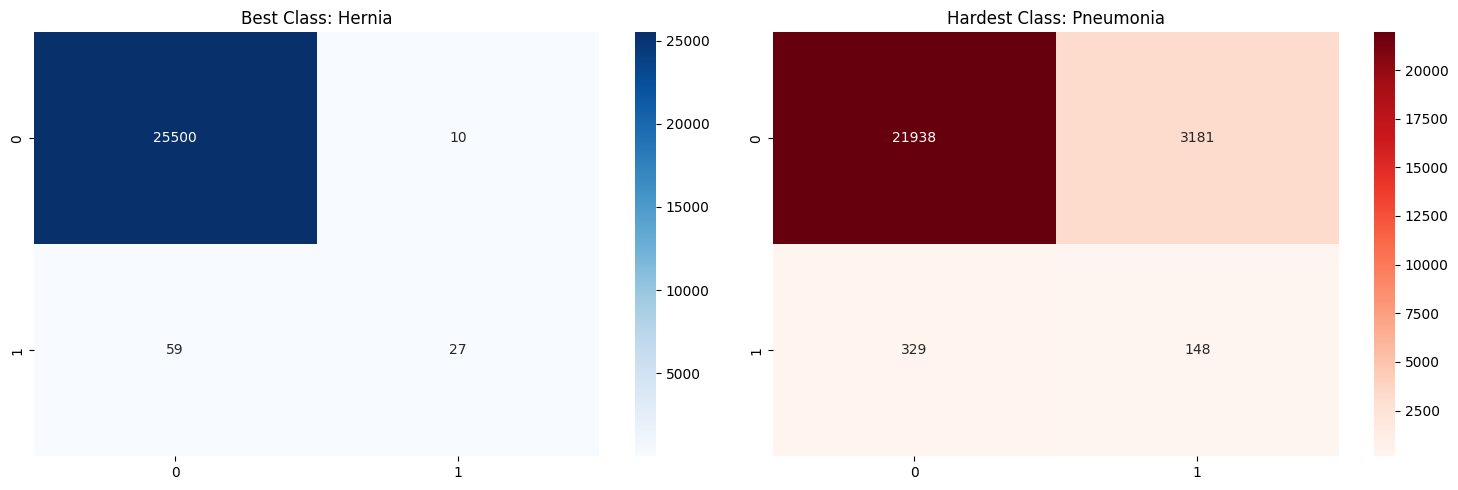

In [7]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

def final_evaluation(model, test_loader, thresholds, device, class_names):
    model.eval()
    all_preds = []
    all_targets = []

    print("🚀 Starting Final Evaluation with Multi-Scale TTA...")
    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs = imgs.to(device)
            with torch.amp.autocast('cuda'):
                p = advanced_tta_predict(model, imgs)
            all_preds.append(p.cpu().numpy())
            all_targets.append(lbls.numpy())

    preds = np.vstack(all_preds)
    targets = np.vstack(all_targets)

    results = []
    for i, name in enumerate(class_names):
        auc = roc_auc_score(targets[:, i], preds[:, i])

        binary_preds = (preds[:, i] > thresholds[i]).astype(int)

        f1 = f1_score(targets[:, i], binary_preds, zero_division=0)

        results.append({
            "Disease": name,
            "AUROC": auc,
            "F1": f1,
            "Threshold": thresholds[i]
        })

    results_df = pd.DataFrame(results)

    print("\n" + "="*55)
    print(f"{'DISEASE':<22} | {'AUROC':<8} | {'F1':<8} | {'THRESH':<8}")
    print("-" * 55)
    for _, row in results_df.iterrows():
        print(f"{row['Disease']:<22} | {row['AUROC']:.4f} | {row['F1']:.4f} | {row['Threshold']:.4f}")
    print("-" * 55)
    print(f"{'MEAN TOTAL':<22} | {results_df['AUROC'].mean():.4f} | {results_df['F1'].mean():.4f}")
    print("="*55)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    best_cls_idx = results_df['AUROC'].idxmax()
    cm_best = confusion_matrix(targets[:, best_cls_idx], (preds[:, best_cls_idx] > thresholds[best_cls_idx]).astype(int))
    sns.heatmap(cm_best, annot=True, fmt='d', ax=axes[0], cmap='Blues')
    axes[0].set_title(f"Best Class: {class_names[best_cls_idx]}")

    try:
        pneu_idx = class_names.index("Pneumonia")
        cm_p = confusion_matrix(targets[:, pneu_idx], (preds[:, pneu_idx] > thresholds[pneu_idx]).astype(int))
        sns.heatmap(cm_p, annot=True, fmt='d', ax=axes[1], cmap='Reds')
        axes[1].set_title(f"Hardest Class: Pneumonia")
    except ValueError:
        pass

    plt.tight_layout()
    plt.show()
    return results_df

model.load_state_dict(torch.load("/kaggle/working/final_best_model_320_enhanced.pth"))
best_thresh_optimized = np.load("/kaggle/working/best_thresholds_320.npy")

test_results = final_evaluation(
    model,
    val_loader,
    best_thresh_optimized,
    DEVICE,
    DISEASE_CLASSES
)

✅ Final 320px Enhanced Model Loaded for Prediction.


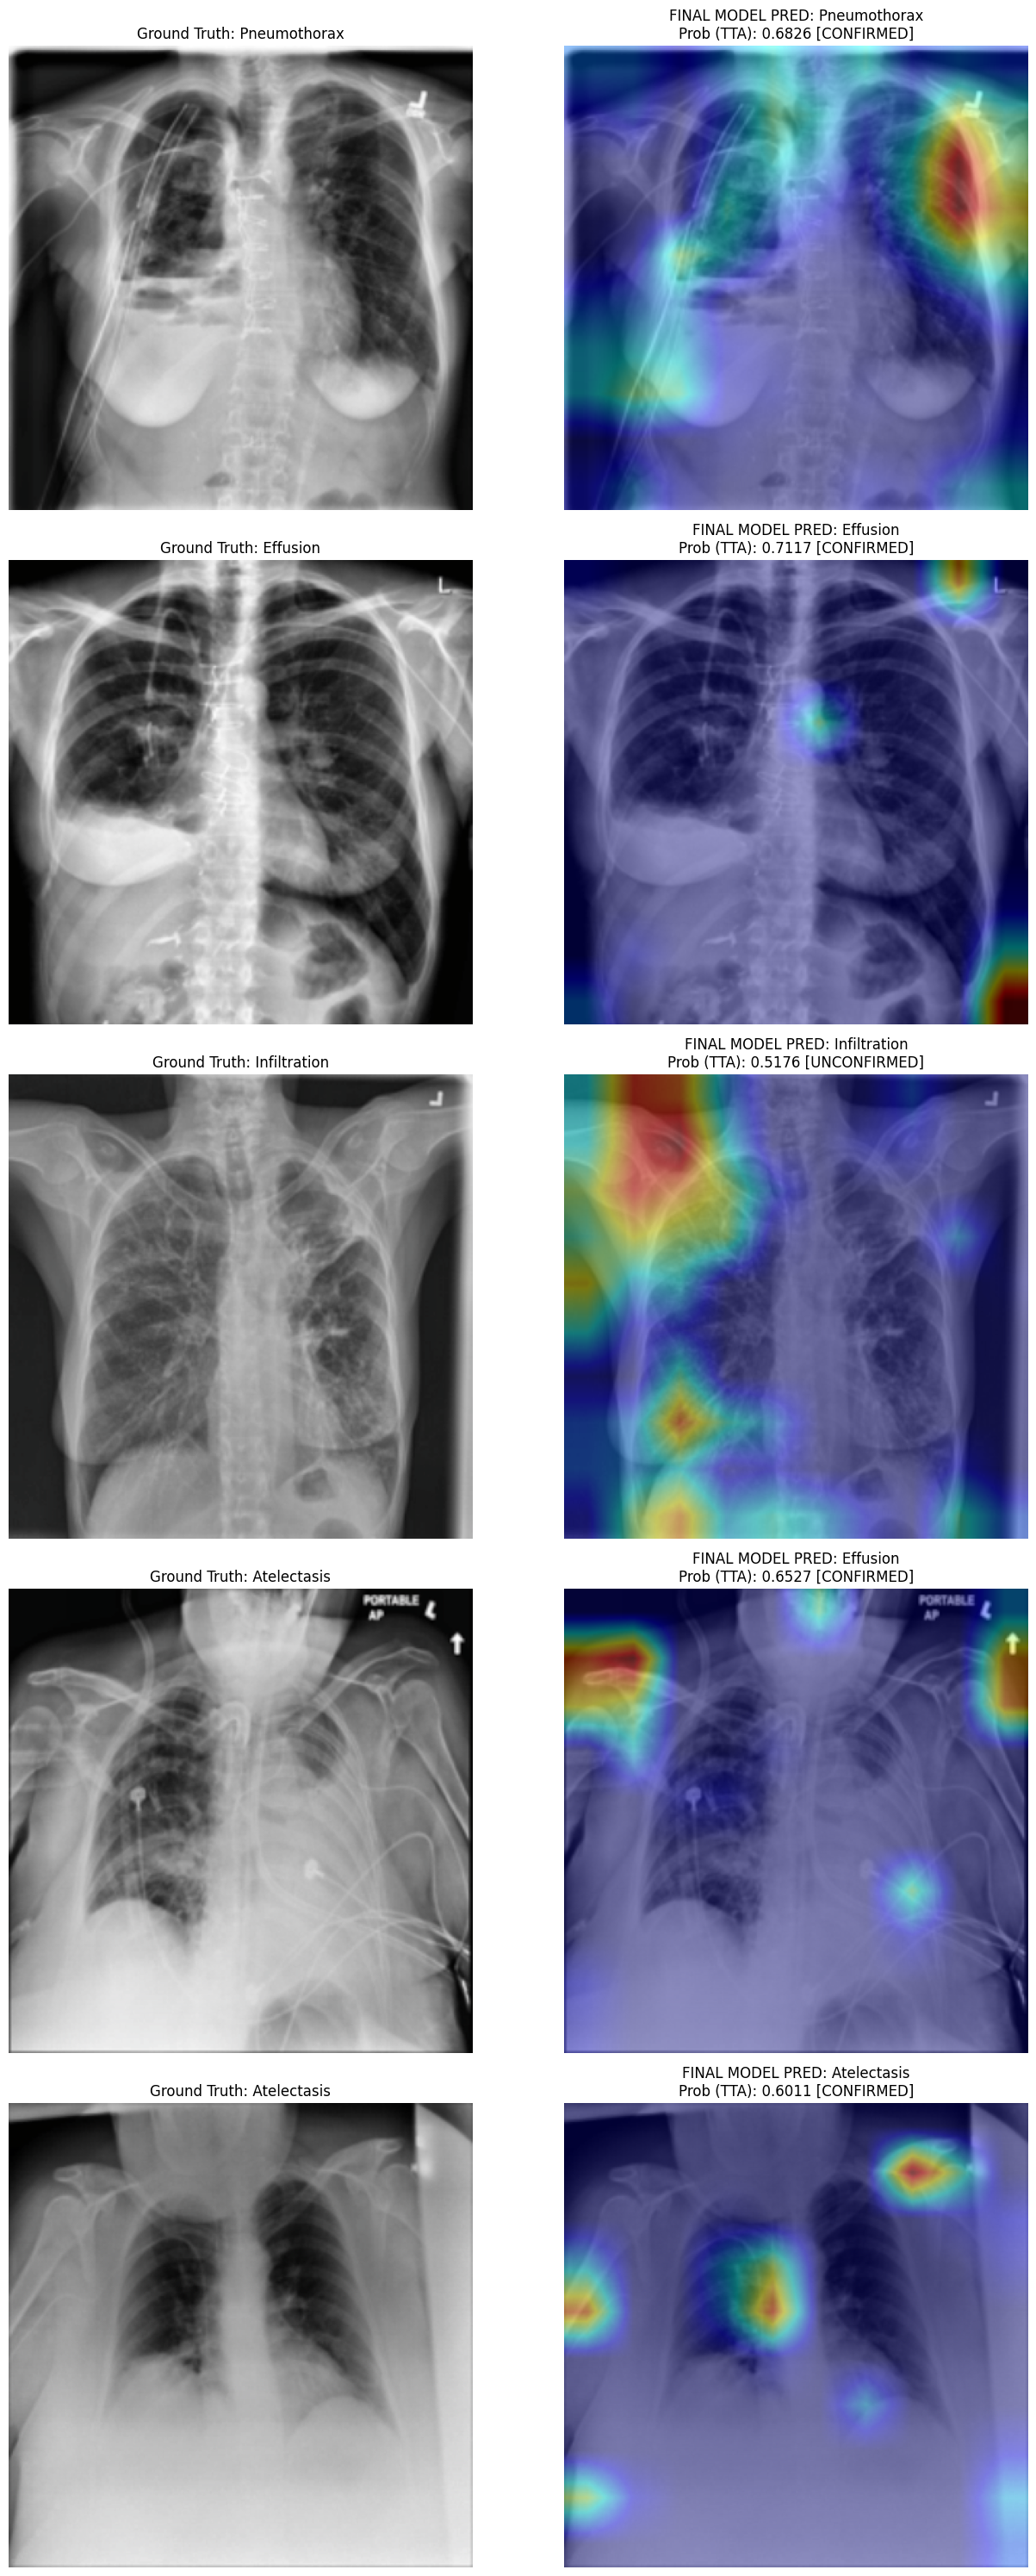

In [12]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
import random

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.target_layer.register_forward_hook(self.save_activations)
        self.target_layer.register_full_backward_hook(self.save_gradients)

    def save_activations(self, module, input, output):
        self.activations = output

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, class_idx):
        self.model.zero_grad()
        output = self.model(input_image)
        loss = output[0, class_idx]
        loss.backward()

        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activated_features = self.activations.detach().clone()
        for i in range(activated_features.shape[1]):
            activated_features[:, i, :, :] *= pooled_gradients[i]

        heatmap = torch.mean(activated_features, dim=1).squeeze()
        heatmap = np.maximum(heatmap.cpu().numpy(), 0)
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)
        return heatmap

def predict_with_final_model(model, dataset, thresholds, class_names, num_samples=5):
    model.load_state_dict(torch.load("/kaggle/working/final_best_model_320_enhanced.pth"))
    model.eval()
    print("✅ Final 320px Enhanced Model Loaded for Prediction.")

    target_layer = None
    for name, module in model.named_modules():
        if isinstance(module, torch.nn.BatchNorm2d) and "norm5" in name:
            target_layer = module
            break
    if target_layer is None:
        target_layer = [m for m in model.backbone.modules() if isinstance(m, torch.nn.BatchNorm2d)][-1]

    cam = GradCAM(model, target_layer)
    indices = random.sample(range(len(dataset)), num_samples)
    fig, axes = plt.subplots(num_samples, 2, figsize=(14, 6 * num_samples))

    for i, idx in enumerate(indices):
        img, label = dataset[idx]
        input_tensor = img.unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            probs_tta = advanced_tta_predict(model, input_tensor).squeeze().cpu().numpy()

        target_cls = np.argmax(probs_tta)

        heatmap = cam.generate_heatmap(input_tensor, target_cls)

        img_np = img.permute(1, 2, 0).cpu().numpy()
        img_np = np.clip(np.array([0.229, 0.224, 0.225]) * img_np + np.array([0.485, 0.456, 0.406]), 0, 1)

        heatmap_resized = cv2.resize(heatmap, (img_np.shape[1], img_np.shape[0]))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB) / 255.0
        overlay = 0.6 * img_np + 0.4 * heatmap_color

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title(f"Ground Truth: {class_names[np.argmax(label)]}")

        status = "CONFIRMED" if probs_tta[target_cls] > thresholds[target_cls] else "UNCONFIRMED"
        axes[i, 1].imshow(overlay)
        axes[i, 1].set_title(f"FINAL MODEL PRED: {class_names[target_cls]}\n"
                             f"Prob (TTA): {probs_tta[target_cls]:.4f} [{status}]")

        for ax in axes[i]: ax.axis('off')

    plt.tight_layout()
    plt.show()

predict_with_final_model(model, val_ds, best_thresh_optimized, DISEASE_CLASSES)